In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from lab07_engine import (
    Body, Spring, NewtonGravity,
    VelocityVerlet, CircleCollisions, World
)

# Four moving disks
bodies = [
    Body(m=1.0, r=[-5.0, 0.0], v=[ 1.0, 1.0], radius=0.35, name="Body 1"),
    Body(m=1.0, r=[-1.0, 0.0], v=[-1.0, 1.0], radius=0.35, name="Body 2"),
    Body(m=1.0, r=[ 1.0, 0.0], v=[ 1.0, 1.0], radius=0.35, name="Body 3"),
    Body(m=1.0, r=[ 5.0, 0.0], v=[-1.0, 1.0], radius=0.35, name="Body 4")
]

# Two distinct force types:
# 1. Springs between adjacent bodies
# 2. Mutual Newtonian gravitational attraction
forces = [
    Spring(i=0, j=1, k=0.1, L0=2.0),
    Spring(i=1, j=2, k=0.1, L0=2.0),
    Spring(i=2, j=3, k=0.1, L0=2.0),
    NewtonGravity(G=0.02, soft=0.1)
]

collisions = CircleCollisions(e=1.0)

world = World(
    integrator=VelocityVerlet(),
    bodies=bodies,
    forces=forces,
    constraints=[collisions]
)

print("Number of bodies:", len(world.bodies))
print("Number of force objects:", len(world.forces))
print("Collision restitution:", collisions.e)

Number of bodies: 4
Number of force objects: 4
Collision restitution: 1.0


In [3]:
world.record("time", lambda w: w.t)

for i in range(4):
    world.record(f"x{i}", lambda w, j=i: w.bodies[j].r[0])
    world.record(f"y{i}", lambda w, j=i: w.bodies[j].r[1])

world.record("kinetic", lambda w: w.kinetic_energy())
world.record("potential", lambda w: w.potential_energy())
world.record("energy", lambda w: w.total_energy())

world.record("px", lambda w: w.momentum()[0])
world.record("py", lambda w: w.momentum()[1])

data = world.run(dt=0.001, t_end=4.0)

print("Simulation finished.")
print("Collision resolutions:", collisions.count)

Simulation finished.
Collision resolutions: 3


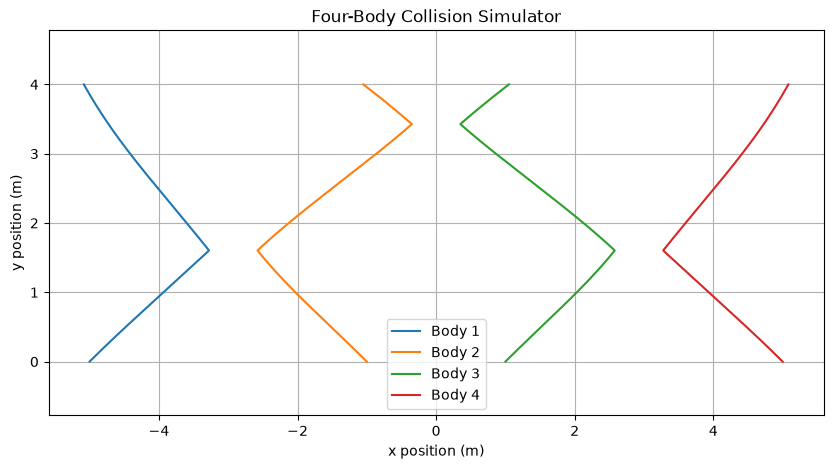

In [4]:
plt.figure(figsize=(10, 5))

for i in range(4):
    plt.plot(data[f"x{i}"], data[f"y{i}"], label=f"Body {i+1}")

plt.xlabel("x position (m)")
plt.ylabel("y position (m)")
plt.title("Four-Body Collision Simulator")
plt.axis("equal")
plt.legend()
plt.grid(True)
plt.show()

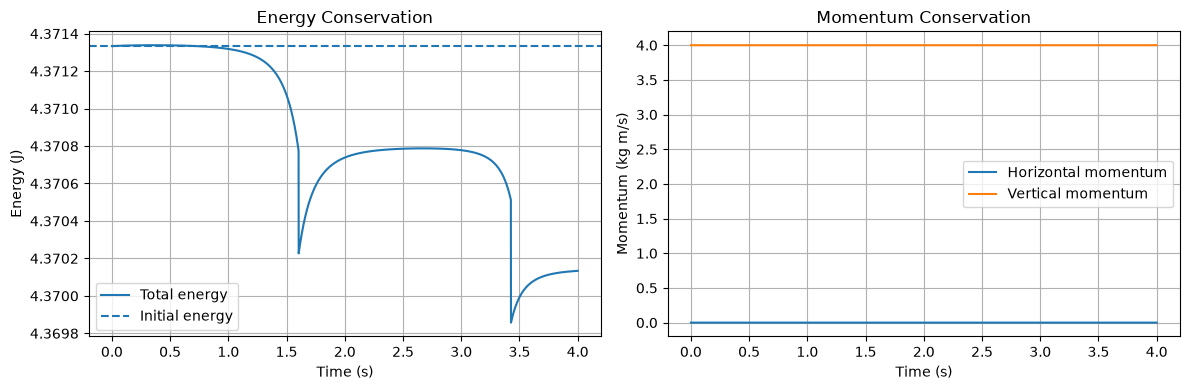

Initial energy: 4.37133333 J
Final energy:   4.37013358 J
Maximum relative energy error: 3.377e-04
Maximum momentum deviation: 1.110e-16 kg m/s


In [5]:
t = data["time"]

E0 = data["energy"][0]
px0 = data["px"][0]
py0 = data["py"][0]

relative_energy_error = (data["energy"] - E0) / abs(E0)

momentum_error = np.sqrt(
    (data["px"] - px0)**2 +
    (data["py"] - py0)**2
)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(t, data["energy"], label="Total energy")
ax[0].axhline(E0, linestyle="--", label="Initial energy")
ax[0].set_xlabel("Time (s)")
ax[0].set_ylabel("Energy (J)")
ax[0].set_title("Energy Conservation")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(t, data["px"], label="Horizontal momentum")
ax[1].plot(t, data["py"], label="Vertical momentum")
ax[1].set_xlabel("Time (s)")
ax[1].set_ylabel("Momentum (kg m/s)")
ax[1].set_title("Momentum Conservation")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

print(f"Initial energy: {E0:.8f} J")
print(f"Final energy:   {data['energy'][-1]:.8f} J")
print(f"Maximum relative energy error: "
      f"{np.max(np.abs(relative_energy_error)):.3e}")
print(f"Maximum momentum deviation: {np.max(momentum_error):.3e} kg m/s")

In [6]:
max_energy_error = np.max(np.abs(relative_energy_error))
max_momentum_error = np.max(momentum_error)

print("VALIDATION SUMMARY")
print("------------------")
print("Bodies:", len(bodies))
print("Force types: Spring and NewtonGravity")
print("Integrator:", world.integrator.name)
print("Collision resolutions:", collisions.count)
print(f"Maximum relative energy error: {max_energy_error:.3e}")
print(f"Maximum momentum deviation: {max_momentum_error:.3e} kg m/s")

VALIDATION SUMMARY
------------------
Bodies: 4
Force types: Spring and NewtonGravity
Integrator: Velocity Verlet
Collision resolutions: 3
Maximum relative energy error: 3.377e-04
Maximum momentum deviation: 1.110e-16 kg m/s


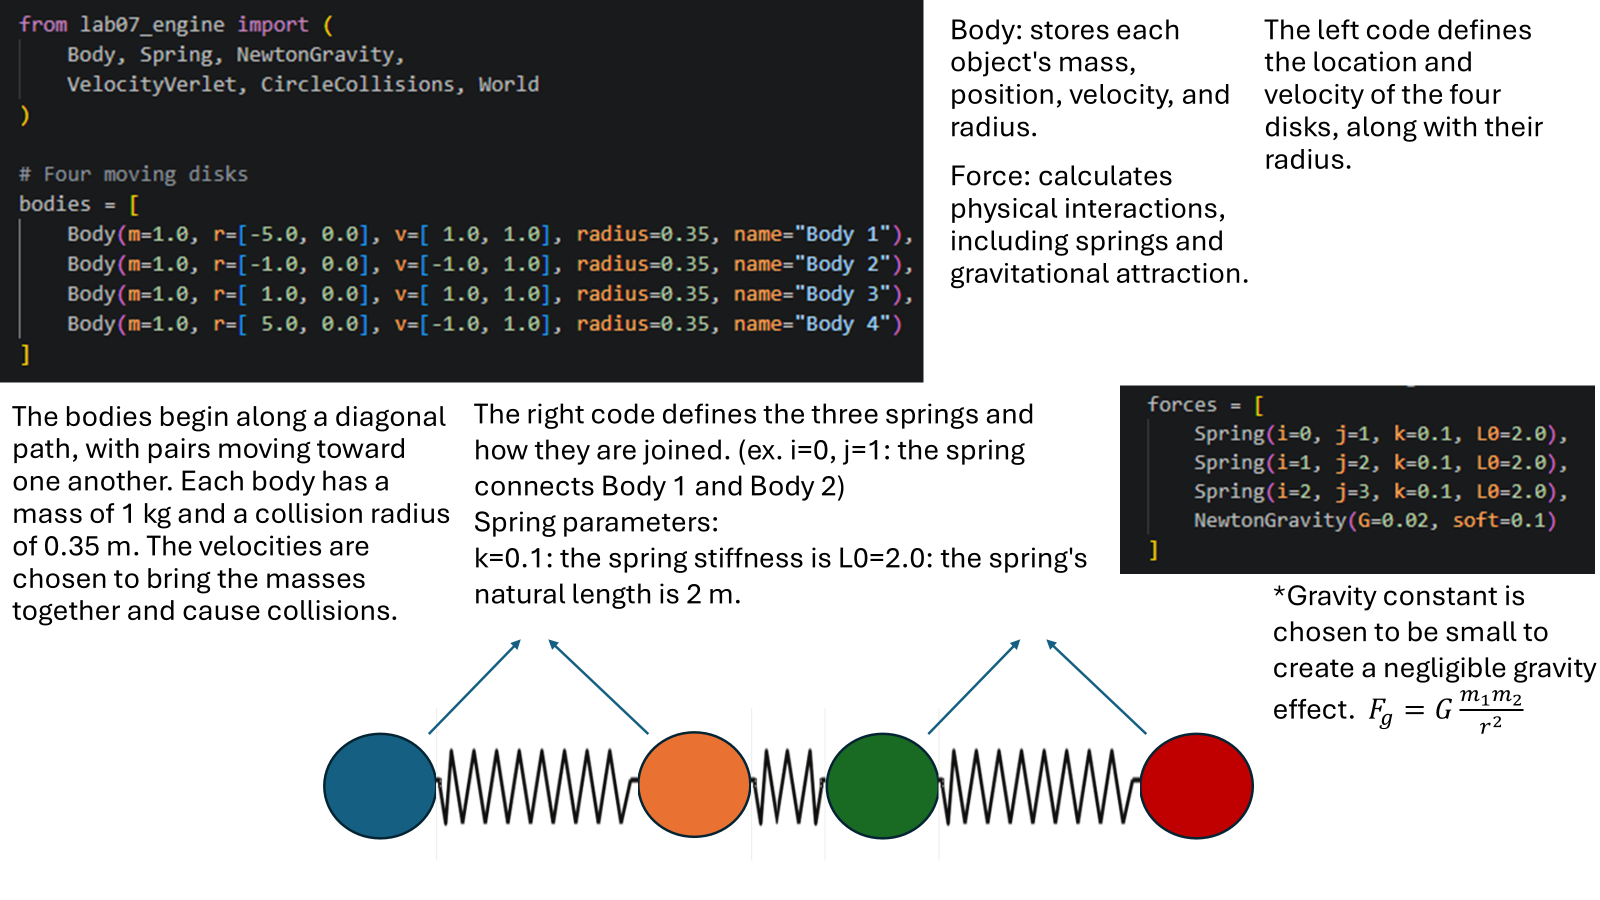

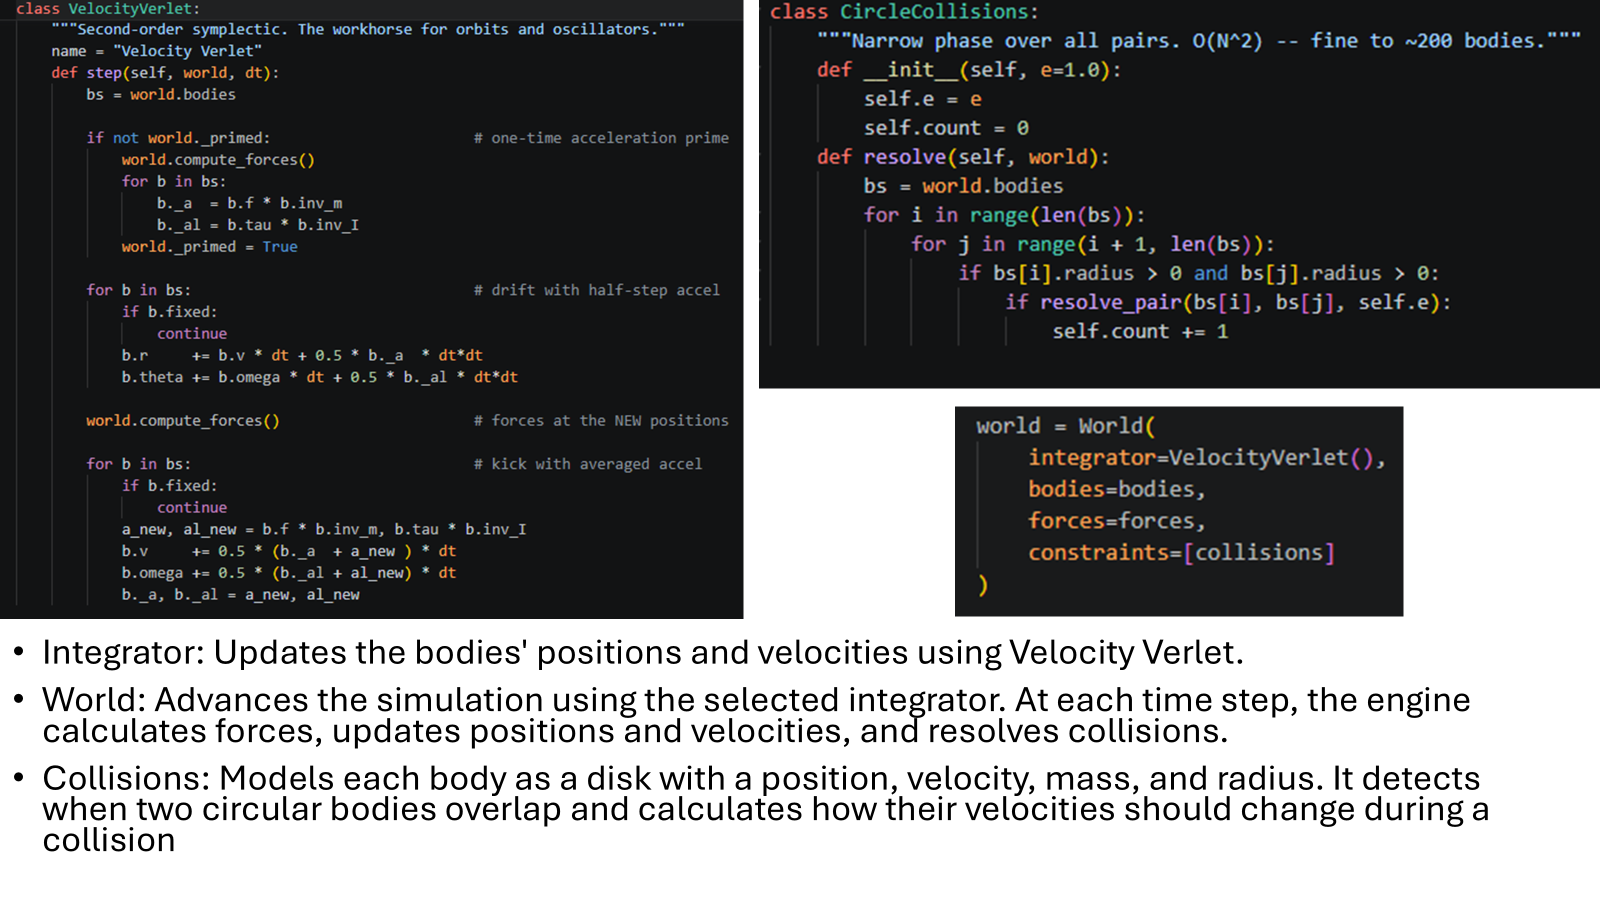

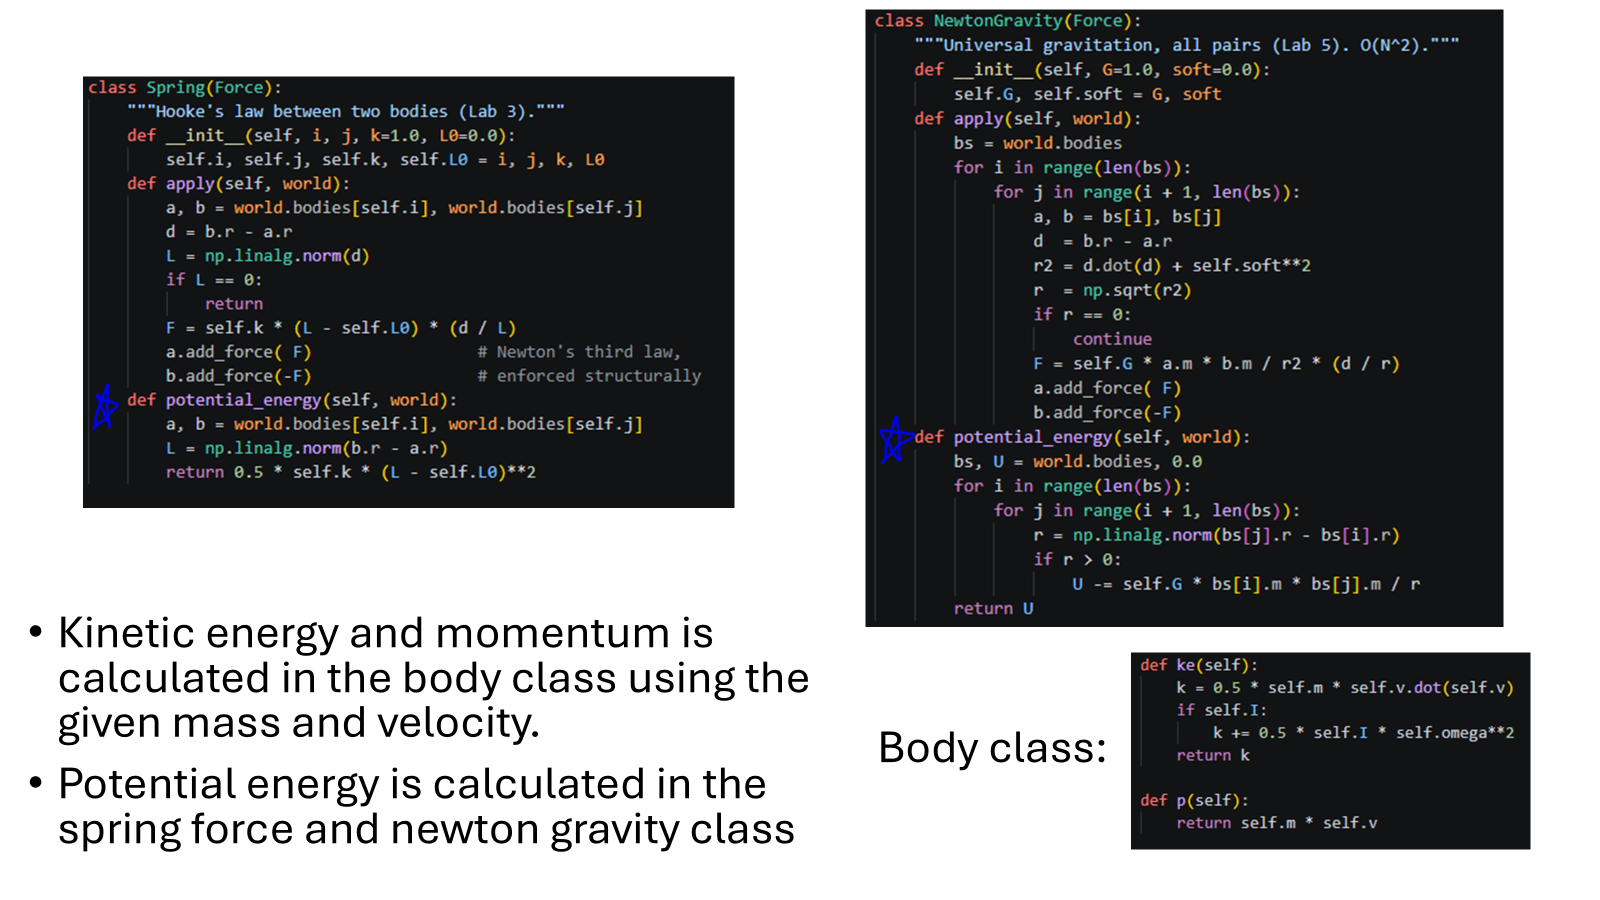

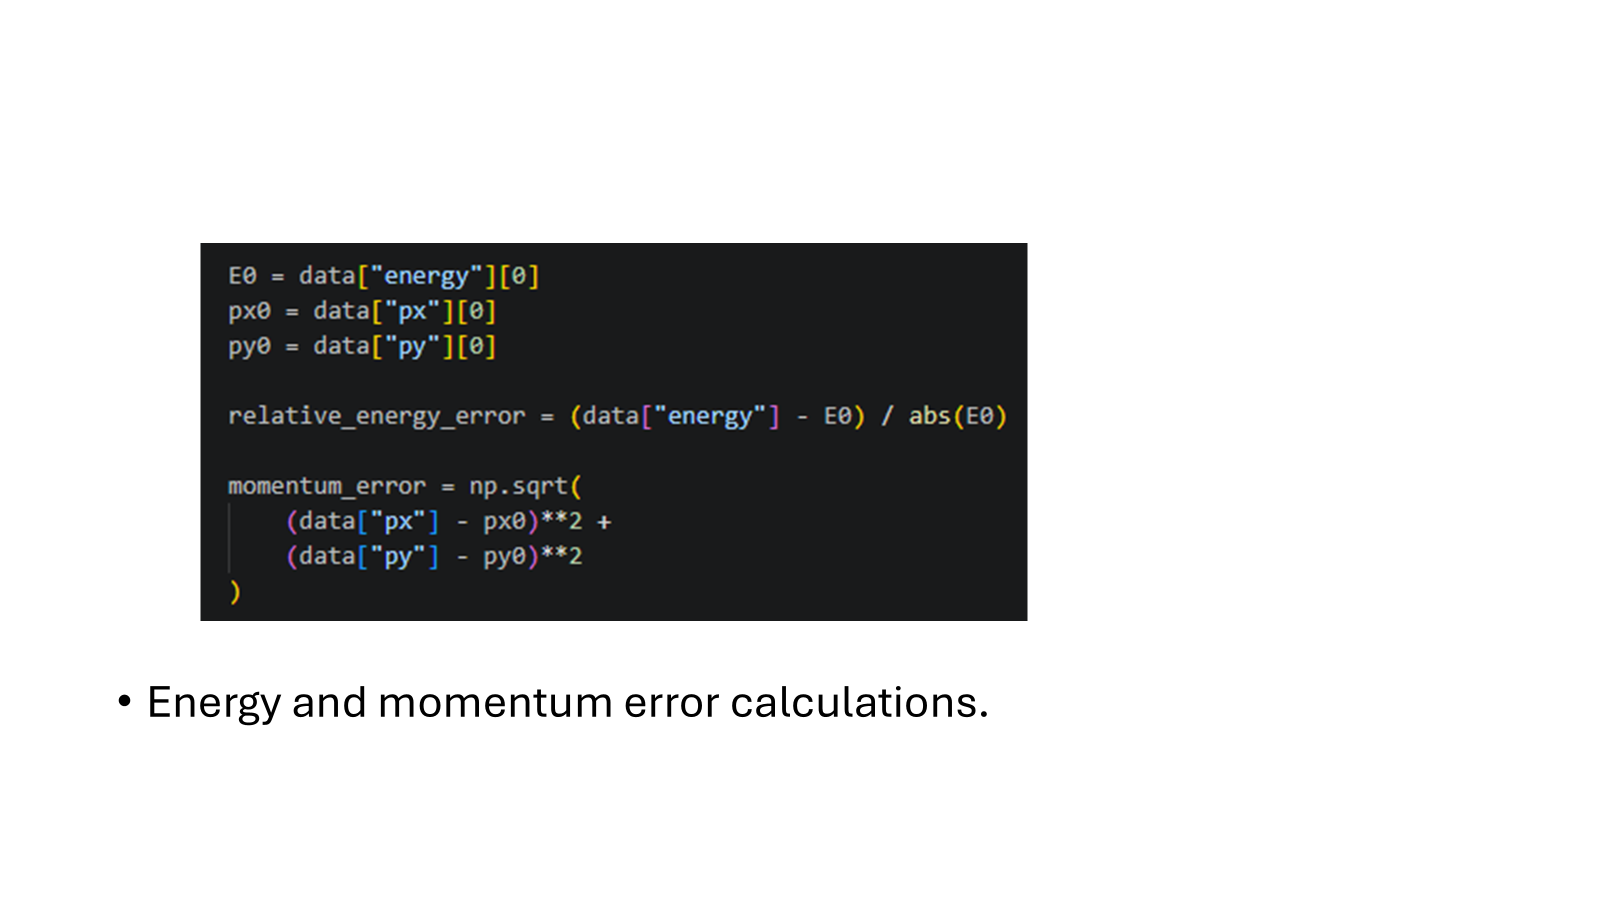